In [1]:
# =============================================================
# [synthetic_anomaly.ipynb - Cell 1] 입력 로드 및 검증
# 목적: 가상 이상 생성 전에 두 입력 파일을 읽고 구조를 확인한다.
#   - ../output/mct_clean.csv                (실제 전처리 데이터, 읽기 전용)
#   - ../reports/model_eda/normal_baseline_by_tool.csv (공구별 정상 기준)
# 주의: mct_clean.csv는 수정/덮어쓰기 금지. seed 선택/생성 없음.
# =============================================================
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 240)

# --- 경로 정의 (notebooks/ 기준 상대경로) ---
CLEAN_PATH    = Path("../output/mct_clean.csv")
BASELINE_PATH = Path("../reports/model_eda/normal_baseline_by_tool.csv")

# --- 1) mct_clean.csv 로드 (원본 보존: 이 변수는 읽기 전용으로만 사용) ---
clean = pd.read_csv(CLEAN_PATH, encoding="utf-8-sig", low_memory=False)
clean["timestamp"] = pd.to_datetime(
    clean["timestamp"], format="%Y-%m-%d %H:%M:%S,%f", errors="coerce"
)

# --- 2) normal_baseline_by_tool.csv 로드 ---
baseline = pd.read_csv(BASELINE_PATH, encoding="utf-8-sig")

# --- 3) 로드 검증: shape / 컬럼 ---
print("=" * 70)
print("[mct_clean.csv]")
print("shape:", clean.shape)
print("timestamp dtype:", clean["timestamp"].dtype,
      "| 결측:", clean["timestamp"].isna().sum())
print("기간:", clean["timestamp"].min(), "~", clean["timestamp"].max())
print("컬럼:", list(clean.columns))

print("\n" + "=" * 70)
print("[normal_baseline_by_tool.csv]")
print("shape:", baseline.shape)
print("컬럼:", list(baseline.columns))

# 가상 이상 설계에서 참조할 핵심 기준 컬럼이 다 있는지 확인
required_base_cols = [
    "current_tool", "sample_count", "insufficient_data",
    "rpm_median", "load_median", "load_p95", "load_p99",
    "rpm_error_median", "rpm_error_p95", "rpm_error_p99",
    "rpm_std_1min_p95", "load_std_1min_p95", "rpmerr_std_1min_p95",
]
missing = [c for c in required_base_cols if c not in baseline.columns]
print("\n필수 기준 컬럼 누락:", missing if missing else "없음 (모두 존재)")

# --- 4) 절삭 잠정 모집단 규모 확인 (참고용, 여기서 seed 선택은 안 함) ---
cutting_mask = (
    (clean["status"] == "STATUS_RUN")
    & (clean["spindle_rpm"] > 0)
    & (clean["feed_rate"] > 0)
)
print("\n" + "=" * 70)
print("절삭 잠정 모집단 (STATUS_RUN & RPM>0 & FEED>0):",
      f"{int(cutting_mask.sum()):,} 행")

# --- 5) 가상 이상 생성에 쓸 수 있는 공구 목록 (표본 충분 = insufficient_data=False) ---
usable = baseline[~baseline["insufficient_data"]].copy()
usable = usable.sort_values("sample_count", ascending=False)

print("\n[가상 이상 생성 가능 공구 (insufficient_data=False)]")
print("사용 가능 공구 수:", len(usable),
      "| 제외 공구:",
      baseline.loc[baseline["insufficient_data"], "current_tool"].tolist())
print(usable[[
    "current_tool", "sample_count",
    "rpm_median", "load_median", "load_p95", "load_p99",
    "rpm_error_median", "rpm_error_p95", "rpm_error_p99",
    "rpm_std_1min_p95", "load_std_1min_p95", "rpmerr_std_1min_p95",
]].to_string(index=False))

# --- 6) 절삭 모집단 안에서 공구별 실제 가용 행 수 (seed 후보 규모) ---
cut_tool_counts = (clean[cutting_mask]
                   .groupby("current_tool").size()
                   .rename("cutting_rows"))
usable_with_rows = usable[["current_tool", "sample_count"]].merge(
    cut_tool_counts, on="current_tool", how="left"
)
print("\n[생성 가능 공구별 절삭 가용 행 수]")
print(usable_with_rows.to_string(index=False))

print("\n[확인 완료] 다음 단계에서 정상 seed 세그먼트 선택 규칙을 설계합니다.")

[mct_clean.csv]
shape: (481648, 31)
timestamp dtype: datetime64[ns] | 결측: 0
기간: 2026-05-01 00:00:04.522000 ~ 2026-05-31 23:59:57.595000
컬럼: ['timestamp', 'machine', 'feed_rate', 'spindle_rate', 'x_axis', 'y_axis', 'z_axis', 'current_tool', 'x_load', 'y_load', 'z_load', 'spindle_load', 'spindle_rpm', 'delta_spindle_rpm', 'status', 'aut_mode', 'run_mode', 'emergency', 'alarm', 'error_message', 'source_file', 'interval_seconds', 'x_axis_mm', 'y_axis_mm', 'z_axis_mm', 'is_alarm', 'is_emergency', 'is_reset', 'is_spindle_overload', 'is_abnormal_interval', 'has_event']

[normal_baseline_by_tool.csv]
shape: (19, 20)
컬럼: ['current_tool', 'sample_count', 'insufficient_data', 'rpm_median', 'rpm_p95', 'rpm_p99', 'load_median', 'load_p95', 'load_p99', 'feed_median', 'feed_p95', 'feed_p99', 'rpm_error_median', 'rpm_error_p95', 'rpm_error_p99', 'rpm_std_1min_p95', 'load_std_1min_p95', 'rpmerr_std_1min_p95', 'reliability_note', 'basis']

필수 기준 컬럼 누락: 없음 (모두 존재)

절삭 잠정 모집단 (STATUS_RUN & RPM>0 & FEED>0)

In [2]:
# =============================================================
# [synthetic_anomaly.ipynb - Cell 2] 연속 절삭 세그먼트 목록 생성
# 목적: 정상 절삭 모집단을 '끊기지 않는 연속 구간'으로 분리해
#       가상 이상 seed로 쓸 수 있는 정상 구간이 얼마나 되는지 확인.
# 세그먼트 분리 기준:
#   (1) CURRENT_TOOL 변경
#   (2) 이전 행과 시간 간격 > 15초
#   (3) STATUS_RUN & RPM>0 & FEED>0 조건이 끊김 (비절삭 행 개입)
#   (+) 날짜(자정) 변경도 분리 (자정 넘는 세그먼트 방지)
# 주의: seed 선택 / 이상 생성 / label 생성 없음. clean 원본 수정 없음.
# =============================================================

# clean 은 Cell 1에서 로드된 원본(읽기 전용). 시간순 정렬본을 따로 만든다.
d = clean.sort_values("timestamp").reset_index(drop=True).copy()

# --- 절삭 여부 플래그 ---
d["is_cutting"] = (
    (d["status"] == "STATUS_RUN")
    & (d["spindle_rpm"] > 0)
    & (d["feed_rate"] > 0)
)

# 절삭 행만 추출 (원본 인덱스/순서 유지)
cut = d[d["is_cutting"]].copy()
cut["date"] = cut["timestamp"].dt.date

# --- 연속성 판정: 아래 중 하나라도 참이면 '새 세그먼트 시작' ---
# 시간 간격(직전 절삭행과의 차이, 초)
gap_sec = cut["timestamp"].diff().dt.total_seconds()
# 공구 변경
tool_change = cut["current_tool"].ne(cut["current_tool"].shift())
# 날짜 변경
date_change = cut["date"].ne(cut["date"].shift())
# 원본 인덱스가 연속이 아니면 = 사이에 비절삭 행이 끼어든 것 (조건 (3))
idx_break = cut.index.to_series().diff().ne(1)

new_seg = (
    gap_sec.isna()          # 첫 행
    | (gap_sec > 15)        # (2) 시간 간격 > 15초
    | tool_change           # (1) 공구 변경
    | date_change           # (+) 날짜 변경
    | idx_break             # (3) 비절삭 행 개입으로 끊김
)
cut["source_segment_id"] = new_seg.cumsum()

# --- 세그먼트별 요약 테이블 ---
seg = (cut.groupby("source_segment_id")
          .agg(current_tool=("current_tool", "first"),
               start_ts=("timestamp", "min"),
               end_ts=("timestamp", "max"),
               n_rows=("timestamp", "size"),
               date=("date", "first"))
          .reset_index())
seg["duration_min"] = ((seg["end_ts"] - seg["start_ts"])
                       .dt.total_seconds() / 60).round(2)

print("=" * 70)
print(f"총 연속 절삭 세그먼트 수: {len(seg):,}")
print(f"세그먼트에 포함된 절삭 행 합계: {seg['n_rows'].sum():,} "
      f"(절삭 모집단 219,195와 일치해야 함)")
print("=" * 70)

# --- 세그먼트 길이 분포 ---
print("\n[세그먼트 행 수 분포]")
print(seg["n_rows"].describe(percentiles=[.5, .9, .99]).round(2).to_string())
print("\n[세그먼트 지속시간(분) 분포]")
print(seg["duration_min"].describe(percentiles=[.5, .9, .99]).round(2).to_string())

# --- 미리보기: 가장 긴 세그먼트 상위 10개 ---
print("\n[가장 긴 세그먼트 상위 10개]")
print(seg.sort_values("n_rows", ascending=False).head(10).to_string(index=False))

# --- 공구별 세그먼트 개수 요약 (전체 / 3분↑ / 5분↑ / 10분↑) ---
def count_by_dur(g, minutes):
    return (g["duration_min"] >= minutes).sum()

summary = (seg.groupby("current_tool")
              .apply(lambda g: pd.Series({
                  "total_segments": len(g),
                  "seg_>=3min": count_by_dur(g, 3),
                  "seg_>=5min": count_by_dur(g, 5),
                  "seg_>=10min": count_by_dur(g, 10),
                  "longest_min": g["duration_min"].max(),
                  "total_cut_rows": g["n_rows"].sum(),
              }), include_groups=False)
              .reset_index())
# 사용 가능 공구(표본 충분) 순으로 보기 좋게 정렬
summary = summary.sort_values("total_cut_rows", ascending=False)

# insufficient_data 공구 표시 (baseline 참조)
insuff = set(baseline.loc[baseline["insufficient_data"], "current_tool"])
summary["insufficient_data"] = summary["current_tool"].isin(insuff)

print("\n" + "=" * 70)
print("[공구별 세그먼트 요약]  (지속시간 기준 개수)")
print("=" * 70)
print(summary.to_string(index=False))

# --- 3분 이상 세그먼트 전체 합계 (seed 확보 가능성 개괄) ---
print("\n[전체 요약]")
for m in [3, 5, 10]:
    print(f"  {m}분 이상 세그먼트 총 개수: {int((seg['duration_min'] >= m).sum()):,}")

# 뒤 단계에서 재사용할 수 있게 보관 (아직 seed 선택 아님)
segment_table = seg.copy()
print("\n[안내] segment_table 생성 완료. 아직 seed 선택/이상 생성은 하지 않았습니다.")

총 연속 절삭 세그먼트 수: 839
세그먼트에 포함된 절삭 행 합계: 219,195 (절삭 모집단 219,195와 일치해야 함)

[세그먼트 행 수 분포]
count     839.00
mean      261.26
std       406.97
min         1.00
50%       139.00
90%       608.00
99%      1826.22
max      5268.00

[세그먼트 지속시간(분) 분포]
count    839.00
mean      25.04
std       39.34
min        0.00
50%       13.31
90%       59.06
99%      175.38
max      521.63

[가장 긴 세그먼트 상위 10개]
 source_segment_id  current_tool                start_ts                  end_ts  n_rows       date  duration_min
                 2            13 2026-05-01 05:19:14.069 2026-05-01 14:00:51.600    5268 2026-05-01        521.63
               643            16 2026-05-23 01:58:27.339 2026-05-23 08:21:34.210    4009 2026-05-23        383.11
                 1            14 2026-05-01 00:00:04.522 2026-05-01 05:17:52.067    3204 2026-05-01        317.79
                25             4 2026-05-05 13:26:47.518 2026-05-05 17:24:01.712    2542 2026-05-05        237.24
                29             4 2026-05

In [3]:
# =============================================================
# [synthetic_anomaly.ipynb - Cell 3] 시간순 split + seed 선택 + 이상유형 배정
# 규칙:
#  1) 날짜 기준 시간순 Train70/Val15/Test15 (Random 금지, 세그먼트는 한 split에만)
#  2) seed: insufficient_data=False 공구 / 연속절삭 세그먼트 / 10분 이상 /
#           세그먼트당 최대 1 seed / seed 길이 10분 통일 / 유형 중복사용 금지
#  3) 선택 seed를 load_rise / rpm_instability / rpm_error_drift 에 균등 배정
#  4) 추적정보 기록. (센서 수정/이상 생성 없음)
# 입력: segment_table(Cell2), clean/baseline(Cell1)
# =============================================================
SEED_MINUTES = 10           # seed 길이 통일
MIN_SEG_MINUTES = 10        # 최소 세그먼트 길이
ANOMALY_TYPES = ["load_rise", "rpm_instability", "rpm_error_drift"]

seg = segment_table.copy()

# --- 1) 날짜 기준 시간순 split (70/15/15) ---
dates = sorted(seg["date"].unique())
n = len(dates)
n_train = int(round(n * 0.70))
n_val   = int(round(n * 0.15))
train_dates = set(dates[:n_train])
val_dates   = set(dates[n_train:n_train + n_val])
test_dates  = set(dates[n_train + n_val:])

def which_split(dt):
    if dt in train_dates: return "train"
    if dt in val_dates:   return "validation"
    return "test"

seg["split"] = seg["date"].map(which_split)  # 세그먼트 단위 → 한 split에만 속함

print("[날짜 분할]")
print(f"  train:      {min(train_dates)} ~ {max(train_dates)} ({len(train_dates)}일)")
print(f"  validation: {min(val_dates)} ~ {max(val_dates)} ({len(val_dates)}일)")
print(f"  test:       {min(test_dates)} ~ {max(test_dates)} ({len(test_dates)}일)")

# --- 2) seed 후보 필터 ---
insuff = set(baseline.loc[baseline["insufficient_data"], "current_tool"])
cand = seg[(~seg["current_tool"].isin(insuff))       # 표본 충분 공구만
           & (seg["duration_min"] >= MIN_SEG_MINUTES)  # 10분 이상
          ].copy()

# 세그먼트당 최대 1 seed → 각 세그먼트 시작 지점부터 10분 구간을 seed로 사용
# (seed_start=세그먼트 시작, seed_end=시작+10분)
cand["seed_start"] = cand["start_ts"]
cand["seed_end"]   = cand["start_ts"] + pd.Timedelta(minutes=SEED_MINUTES)
# 안전장치: 세그먼트 종료 전에 10분이 확보되는지 (10분 이상이라 충족되지만 명시 검증)
cand = cand[cand["seed_end"] <= cand["end_ts"]].copy()

# --- 공구·날짜에 최대한 분산되도록 정렬 후 선택 ---
# 세그먼트당 1개이므로 후보 = 그대로 seed. 분산을 위해 (날짜, 공구) 순으로 섞어 정렬.
cand = cand.sort_values(["date", "current_tool", "source_segment_id"]).reset_index(drop=True)

# --- 3) 이상 유형 균등 배정 (split 내부 라운드로빈 → 유형 편중 방지) ---
# groupby.apply 대신 split별로 직접 순회 (pandas 최신버전 호환)
parts = []
for sp in ["train", "validation", "test"]:
    g = cand[cand["split"] == sp].sort_values(
        ["date", "current_tool", "source_segment_id"]
    ).reset_index(drop=True)
    g["assigned_anomaly_type"] = [ANOMALY_TYPES[i % 3] for i in range(len(g))]
    parts.append(g)

seeds = pd.concat(parts, ignore_index=True)

# --- 4) 추적 테이블 정리 ---
seed_table = seeds[[
    "source_segment_id", "split", "current_tool",
    "seed_start", "seed_end", "date", "assigned_anomaly_type", "n_rows"
]].rename(columns={"date": "source_date"}).reset_index(drop=True)

# 다음 셀에서 사용
seed_table_final = seed_table.copy()

# ---------------- 요약 출력 ----------------
print("\n" + "=" * 60)
print(f"선택된 seed 총 개수: {len(seed_table)}")
print("=" * 60)

print("\n[split별 seed 개수]")
print(seed_table["split"].value_counts()
      .reindex(["train", "validation", "test"]).to_string())

print("\n[이상 유형별 seed 개수]")
print(seed_table["assigned_anomaly_type"].value_counts()
      .reindex(ANOMALY_TYPES).to_string())

print("\n[공구별 seed 개수]")
print(seed_table["current_tool"].value_counts().sort_index().to_string())

print("\n[split × 이상유형 교차 확인]")
print(pd.crosstab(seed_table["split"], seed_table["assigned_anomaly_type"]))

print("\n[미리보기 상위 8개]")
print(seed_table.head(8).to_string(index=False))
print("\n[안내] seed 선택/배정 완료. 센서 수정·이상 생성은 Cell 4에서 진행합니다.")

[날짜 분할]
  train:      2026-05-01 ~ 2026-05-21 (19일)
  validation: 2026-05-22 ~ 2026-05-26 (4일)
  test:       2026-05-27 ~ 2026-05-30 (4일)

선택된 seed 총 개수: 462

[split별 seed 개수]
split
train         363
validation     43
test           56

[이상 유형별 seed 개수]
assigned_anomaly_type
load_rise          155
rpm_instability    154
rpm_error_drift    153

[공구별 seed 개수]
current_tool
1     100
2       1
3      67
4     126
5      19
6      40
8      31
10     28
11      4
12      1
13     16
14      2
15      3
16      3
18     10
19     11

[split × 이상유형 교차 확인]
assigned_anomaly_type  load_rise  rpm_error_drift  rpm_instability
split                                                             
test                          19               18               19
train                        121              121              121
validation                    15               14               14

[미리보기 상위 8개]
 source_segment_id split  current_tool              seed_start                seed_end source_da

In [4]:
# =============================================================
# [synthetic_anomaly.ipynb - Cell 4] 가상 이상 3종 시계열 생성
# 각 10분 seed 구조: 0~3분 normal(원본유지) / 3~6분 warning(점진증가) / 6~10분 anomaly(유지)
# label: normal=0, warning+anomaly=1 / stage 컬럼 별도 유지
# 강도: normal_baseline_by_tool.csv 공구별 기준 상대변형 (절대값 하드코딩 금지)
# 원본 clean 수정 금지 → seed 구간 복사본만 변형
# =============================================================
NORMAL_END = 3.0    # 분
WARN_END   = 6.0    # 분  (3~6 warning, 6~10 anomaly)
SEED_MIN   = 10.0

rng = np.random.default_rng(42)   # 재현성

# baseline을 공구별 dict로 (빠른 조회)
base_by_tool = baseline.set_index("current_tool").to_dict("index")

# clean에 원본 순서 인덱스 부여 (seed 구간 슬라이싱용, 원본은 안 건드림)
src = clean.sort_values("timestamp").reset_index(drop=True)
src_ts = src["timestamp"]

def stage_of(minute):
    if minute < NORMAL_END: return "normal"
    if minute < WARN_END:   return "warning"
    return "anomaly"

def ramp(minute):
    """warning: 0→1 선형 증가, anomaly: 1 유지, normal: 0"""
    if minute < NORMAL_END: return 0.0
    if minute < WARN_END:   return (minute - NORMAL_END) / (WARN_END - NORMAL_END)
    return 1.0

def make_load_rise(seg, b, mins):
    """SPINDLE_LOAD를 load_p99 기준 배수까지 점진 상승. RPM/RATE/축부하 불변."""
    out = seg["spindle_load"].astype(float).values.copy()
    p95, p99 = b["load_p95"], b["load_p99"]
    target = p99 * 2.0                      # anomaly 목표 = 정상 P99의 2배
    for i, m in enumerate(mins):
        r = ramp(m)
        if r > 0:
            base_val = out[i]
            # warning: base→p95 근처, anomaly: p95→target 로 자연스럽게
            goal = p95 + (target - p95) * r
            # 살짝의 요동(정상 변동 수준)만 추가해 계단모양 방지
            noise = rng.normal(0, max(b["load_std_1min_p95"], 0.5) * 0.5)
            out[i] = max(base_val, goal) + noise
    return {"spindle_load": np.round(out, 1)}

def make_rpm_instability(seg, b, mins):
    """SPINDLE_RPM에 변동성 주입(평균 유지). SPINDLE_RATE(지령) 불변."""
    rpm = seg["spindle_rpm"].astype(float).values.copy()
    base_std = max(b["rpm_std_1min_p95"], 3.0)   # 0인 공구는 하한 3
    mean_rpm = np.mean(rpm[[i for i,m in enumerate(mins) if m < NORMAL_END]] ) \
               if any(m < NORMAL_END for m in mins) else np.mean(rpm)
    # 자기상관 있는 흔들림 (백색잡음 티 방지): 느린 드리프트 + 미세진동
    wob = 0.0
    for i, m in enumerate(mins):
        r = ramp(m)
        if r > 0:
            amp = base_std * (1 + 14 * r)        # 정상std의 최대 ~15배까지 진폭 확대
            wob = 0.7 * wob + 0.3 * rng.normal(0, amp)   # AR(1) 성격
            rpm[i] = mean_rpm + wob
    return {"spindle_rpm": np.round(rpm).astype(int)}

def make_rpm_error_drift(seg, b, mins):
    """SPINDLE_RPM을 이동시켜 RPM_ERROR(=RATE-RPM)를 정상범위 밖으로 이탈. RATE 불변."""
    rate = seg["spindle_rate"].astype(float).values.copy()
    rpm  = seg["spindle_rpm"].astype(float).values.copy()
    med  = b["rpm_error_median"]                 # 공구 정상 편차 중심
    p95, p99 = b["rpm_error_p95"], b["rpm_error_p99"]
    # 정상 대역폭(중심에서 P99까지 거리), 최소 5 보장
    halfband = max(abs(p99 - med), abs(p95 - med), 5.0)
    target_err = med + np.sign(p99 - med if p99 != med else 1) * halfband * 6.0  # 정상밖 6배 이탈
    for i, m in enumerate(mins):
        r = ramp(m)
        if r > 0:
            goal_err = med + (target_err - med) * r
            # RPM_ERROR = RATE - RPM  →  RPM = RATE - goal_err
            noise = rng.normal(0, max(b["rpmerr_std_1min_p95"], 0.5) * 0.5)
            rpm[i] = rate[i] - (goal_err + noise)
    return {"spindle_rpm": np.round(rpm).astype(int)}

GENERATORS = {
    "load_rise":       make_load_rise,
    "rpm_instability": make_rpm_instability,
    "rpm_error_drift": make_rpm_error_drift,
}

# --- seed 순회하며 생성 ---
synthetic_parts = []
skipped = []

for _, s in seed_table_final.iterrows():
    tool = s["current_tool"]
    b = base_by_tool.get(tool)
    if b is None:
        skipped.append((s["source_segment_id"], "no_baseline")); continue

    # 원본에서 seed 구간(10분) 슬라이스 → 복사본
    m = (src_ts >= s["seed_start"]) & (src_ts < s["seed_end"])
    seg = src.loc[m].copy()
    if len(seg) < 5:
        skipped.append((s["source_segment_id"], "too_few_rows")); continue

    # seed 시작 기준 경과분
    mins = ((seg["timestamp"] - s["seed_start"]).dt.total_seconds() / 60).values

    # 이상 유형별 센서 변형 (복사본에만)
    changes = GENERATORS[s["assigned_anomaly_type"]](seg, b, mins)
    for col, vals in changes.items():
        seg[col] = vals

    # RPM_ERROR 계열은 delta_spindle_rpm 재계산 없이 원본 유지(1차 단순화),
    # 파생 rpm_error는 Feature 단계에서 rate-rpm으로 계산하므로 여기선 불필요

    # 추적정보 부여
    seg["stage"]      = [stage_of(mm) for mm in mins]
    seg["label"]      = (seg["stage"] != "normal").astype(int)
    seg["anomaly_type"] = np.where(seg["stage"] == "normal", "normal",
                                   s["assigned_anomaly_type"])
    seg["is_synthetic"]     = True
    seg["source_segment_id"] = s["source_segment_id"]
    seg["split"]            = s["split"]
    seg["seed_tool"]        = tool

    synthetic_parts.append(seg)

synthetic = pd.concat(synthetic_parts, ignore_index=True)

# ---------------- 요약 ----------------
print("=" * 60)
print(f"생성된 synthetic 행 수: {len(synthetic):,}  (seed {len(synthetic_parts)}개)")
print(f"스킵된 seed: {len(skipped)}", skipped[:5] if skipped else "")
print("=" * 60)
print("\n[stage별 행 수]")
print(synthetic["stage"].value_counts().reindex(["normal","warning","anomaly"]).to_string())
print("\n[label별 행 수]  (normal=0 / warning+anomaly=1)")
print(synthetic["label"].value_counts().to_string())
print("\n[anomaly_type별 행 수]")
print(synthetic["anomaly_type"].value_counts().to_string())
print("\n[split별 행 수]")
print(synthetic["split"].value_counts().reindex(["train","validation","test"]).to_string())

# --- 검증용: 한 seed의 변형 전/후 비교 (load_rise 예시) ---
ex = synthetic[synthetic["anomaly_type"] == "load_rise"].groupby("source_segment_id").first().index[0]
ex_seg = synthetic[synthetic["source_segment_id"] == ex]
print(f"\n[검증 미리보기] load_rise seed segment_id={ex}, 공구={ex_seg['seed_tool'].iat[0]}")
print(ex_seg.groupby("stage")["spindle_load"].agg(["mean","max"]).round(1).to_string())

print("\n[안내] 가상 이상 3종 생성 완료(메모리). 저장/Window Feature는 다음 셀에서.")

생성된 synthetic 행 수: 48,240  (seed 462개)
스킵된 seed: 0 

[stage별 행 수]
stage
normal     14647
warning    14392
anomaly    19201

[label별 행 수]  (normal=0 / warning+anomaly=1)
label
1    33593
0    14647

[anomaly_type별 행 수]
anomaly_type
normal             14647
load_rise          11267
rpm_instability    11195
rpm_error_drift    11131

[split별 행 수]
split
train         37977
validation     4458
test           5805

[검증 미리보기] load_rise seed segment_id=2, 공구=13
         mean   max
stage              
anomaly  30.0  30.6
normal   14.8  17.0
warning  22.4  29.7

[안내] 가상 이상 3종 생성 완료(메모리). 저장/Window Feature는 다음 셀에서.


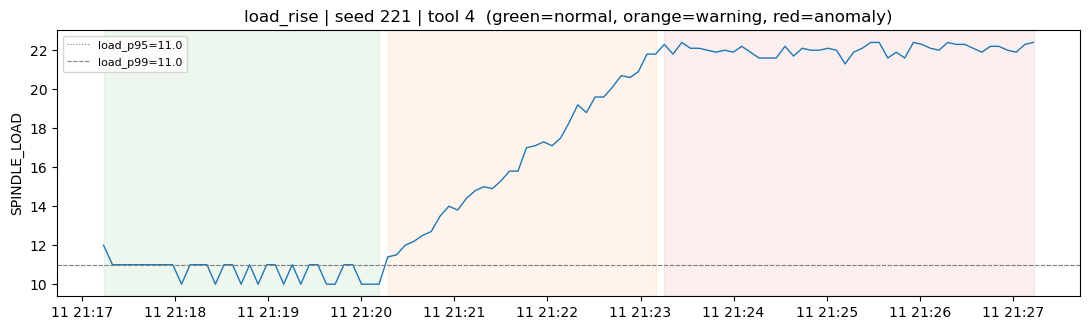

C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:49: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:49: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:49: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:49: UserWarning: Glyph 47564 (\N{HANGUL SYLLABLE MAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:49: UserWarning: Glyph 51613 (\N{HANGUL SYLLABLE JEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py

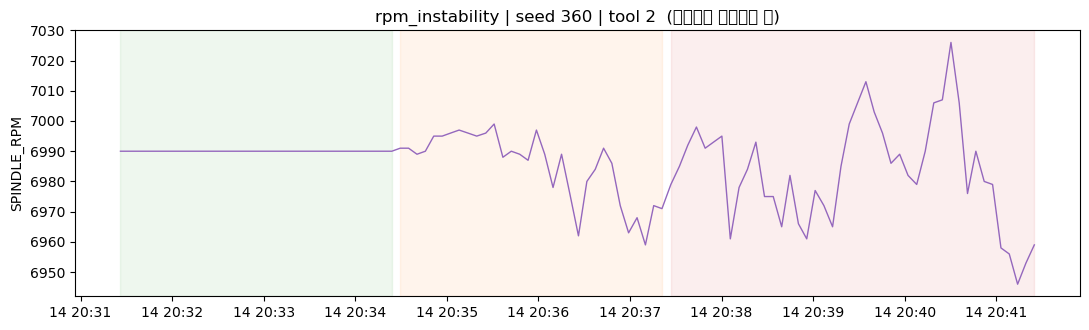

C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:72: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:72: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:72: UserWarning: Glyph 47564 (\N{HANGUL SYLLABLE MAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:72: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:72: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\rbcks\AppData\Local\Temp\ipykernel_12072\2853042709.py:72: UserW

[rpm_instability seed 360, tool 2] stage별 RPM mean/std
           mean   std   min   max
stage                            
normal   6990.0   0.0  6990  6990
warning  6985.0  11.4  6959  6999
anomaly  6983.1  17.5  6946  7026


C:\Users\rbcks\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\rbcks\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\rbcks\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47564 (\N{HANGUL SYLLABLE MAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\rbcks\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\rbcks\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io,

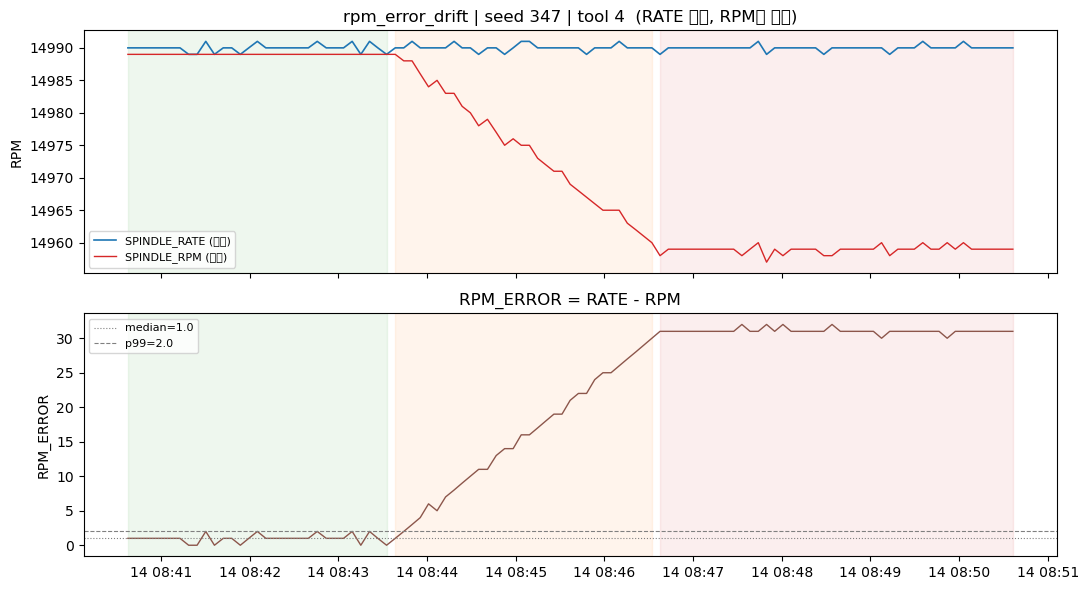

[rpm_error_drift seed 347, tool 4] stage별 RPM_ERROR mean/absmax
         rate_mean  rpm_mean  rpmerr_mean  rpmerr_absmax
stage                                                   
normal     14990.0   14989.0          1.0              2
warning    14990.1   14974.4         15.7             30
anomaly    14990.0   14958.9         31.0             32

[전체 synthetic 범위 검증]
SPINDLE_RPM < 0 : 0 행
SPINDLE_LOAD < 0: 0 행
NaN 총 개수    : 0
inf 총 개수    : 0

원본 절삭 RPM 최대 : 25990   | synthetic RPM 최대: 26034
원본 절삭 LOAD 최대: 85   | synthetic LOAD 최대: 34.9
  synthetic RPM > 원본최대 인 행: 48
  synthetic LOAD> 원본최대 인 행: 0
  synthetic RPM 최소값: 6946

[안내] 검증 완료. 문제 없으면 Cell 6에서 저장합니다. (이 셀은 수정/저장 없음)


In [5]:
# =============================================================
# [synthetic_anomaly.ipynb - Cell 5] 가상 이상 3종 시각화 & 범위 검증 (수정 없음)
# 목적: Cell 4 생성 결과가 의도대로인지 최종 확인만. 재생성/저장 없음.
# =============================================================
import matplotlib.pyplot as plt

STAGE_COLORS = {"normal": "#2ca02c", "warning": "#ff7f0e", "anomaly": "#d62728"}

def shade_stages(ax, seg):
    """stage 구간을 배경색으로 표시"""
    for st in ["normal", "warning", "anomaly"]:
        sub = seg[seg["stage"] == st]
        if len(sub):
            ax.axvspan(sub["timestamp"].min(), sub["timestamp"].max(),
                       color=STAGE_COLORS[st], alpha=0.08)

def pick_seed(atype):
    """해당 유형에서 대표 seed 1개 (행 수가 넉넉한 것)"""
    sub = synthetic[synthetic["anomaly_type"] == atype]
    sizes = sub.groupby("source_segment_id").size().sort_values(ascending=False)
    sid = sizes.index[0]
    return synthetic[synthetic["source_segment_id"] == sid].sort_values("timestamp")

# RPM_ERROR 파생 (검증용, synthetic 원본은 그대로)
synthetic_view = synthetic.copy()
synthetic_view["rpm_error"] = synthetic_view["spindle_rate"] - synthetic_view["spindle_rpm"]

# ---------- 1) load_rise ----------
seg = pick_seed("load_rise")
tool = seg["seed_tool"].iat[0]; sid = seg["source_segment_id"].iat[0]
b = base_by_tool[tool]
fig, ax = plt.subplots(figsize=(11, 3.4))
shade_stages(ax, seg)
ax.plot(seg["timestamp"], seg["spindle_load"], color="#1f77b4", lw=1)
ax.axhline(b["load_p95"], ls=":", color="gray", lw=0.8, label=f"load_p95={b['load_p95']}")
ax.axhline(b["load_p99"], ls="--", color="gray", lw=0.8, label=f"load_p99={b['load_p99']}")
ax.set_title(f"load_rise | seed {sid} | tool {tool}  (green=normal, orange=warning, red=anomaly)")
ax.set_ylabel("SPINDLE_LOAD"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# ---------- 2) rpm_instability ----------
seg = pick_seed("rpm_instability")
tool = seg["seed_tool"].iat[0]; sid = seg["source_segment_id"].iat[0]
fig, ax = plt.subplots(figsize=(11, 3.4))
shade_stages(ax, seg)
ax.plot(seg["timestamp"], seg["spindle_rpm"], color="#9467bd", lw=1)
ax.set_title(f"rpm_instability | seed {sid} | tool {tool}  (변동성만 증가해야 함)")
ax.set_ylabel("SPINDLE_RPM")
plt.tight_layout(); plt.show()

print(f"[rpm_instability seed {sid}, tool {tool}] stage별 RPM mean/std")
print(seg.groupby("stage")["spindle_rpm"].agg(["mean", "std", "min", "max"]).round(1)
      .reindex(["normal", "warning", "anomaly"]).to_string())

# ---------- 3) rpm_error_drift ----------
seg = pick_seed("rpm_error_drift").copy()
seg["rpm_error"] = seg["spindle_rate"] - seg["spindle_rpm"]
tool = seg["seed_tool"].iat[0]; sid = seg["source_segment_id"].iat[0]
b = base_by_tool[tool]

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
shade_stages(ax[0], seg); shade_stages(ax[1], seg)
ax[0].plot(seg["timestamp"], seg["spindle_rate"], color="#1f77b4", lw=1.2, label="SPINDLE_RATE (지령)")
ax[0].plot(seg["timestamp"], seg["spindle_rpm"],  color="#d62728", lw=1, label="SPINDLE_RPM (실제)")
ax[0].set_title(f"rpm_error_drift | seed {sid} | tool {tool}  (RATE 유지, RPM만 이동)")
ax[0].set_ylabel("RPM"); ax[0].legend(fontsize=8)

ax[1].plot(seg["timestamp"], seg["rpm_error"], color="#8c564b", lw=1)
ax[1].axhline(b["rpm_error_median"], ls=":", color="gray", lw=0.8, label=f"median={b['rpm_error_median']}")
ax[1].axhline(b["rpm_error_p99"], ls="--", color="gray", lw=0.8, label=f"p99={b['rpm_error_p99']}")
ax[1].set_title("RPM_ERROR = RATE - RPM"); ax[1].set_ylabel("RPM_ERROR"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"[rpm_error_drift seed {sid}, tool {tool}] stage별 RPM_ERROR mean/absmax")
g = seg.groupby("stage")
print(pd.DataFrame({
    "rate_mean": g["spindle_rate"].mean().round(1),
    "rpm_mean":  g["spindle_rpm"].mean().round(1),
    "rpmerr_mean": g["rpm_error"].mean().round(1),
    "rpmerr_absmax": g["rpm_error"].apply(lambda s: s.abs().max()),
}).reindex(["normal", "warning", "anomaly"]).to_string())

# ---------- 4) 전체 비현실적 값 검증 ----------
print("\n" + "=" * 60)
print("[전체 synthetic 범위 검증]")
print("=" * 60)
s = synthetic_view
print(f"SPINDLE_RPM < 0 : {(s['spindle_rpm'] < 0).sum()} 행")
print(f"SPINDLE_LOAD < 0: {(s['spindle_load'] < 0).sum()} 행")

num_cols = ["spindle_rpm", "spindle_rate", "spindle_load", "feed_rate", "rpm_error"]
nan_cnt = s[num_cols].isna().sum().sum()
inf_cnt = np.isinf(s[num_cols].to_numpy(dtype="float64")).sum()
print(f"NaN 총 개수    : {nan_cnt}")
print(f"inf 총 개수    : {inf_cnt}")

# 원본(clean) 절삭 범위와 비교
cut_src = clean[(clean["status"]=="STATUS_RUN") & (clean["spindle_rpm"]>0) & (clean["feed_rate"]>0)]
rpm_max_src  = cut_src["spindle_rpm"].max()
load_max_src = cut_src["spindle_load"].max()
print(f"\n원본 절삭 RPM 최대 : {rpm_max_src}   | synthetic RPM 최대: {s['spindle_rpm'].max()}")
print(f"원본 절삭 LOAD 최대: {load_max_src}   | synthetic LOAD 최대: {s['spindle_load'].max()}")
print(f"  synthetic RPM > 원본최대 인 행: {(s['spindle_rpm'] > rpm_max_src).sum()}")
print(f"  synthetic LOAD> 원본최대 인 행: {(s['spindle_load'] > load_max_src).sum()}")
print(f"  synthetic RPM 최소값: {s['spindle_rpm'].min()}")

print("\n[안내] 검증 완료. 문제 없으면 Cell 6에서 저장합니다. (이 셀은 수정/저장 없음)")

In [7]:
# =============================================================
# [synthetic_anomaly.ipynb - Cell 6] synthetic 데이터 저장 & 저장 검증
# - synthetic(메모리) 수정/재생성 없이 그대로 저장
# - 저장 후 재로드하여 행 수 동일 여부까지 확인
# - 원본 mct_clean.csv는 손대지 않음 (별도 파일로 저장)
# =============================================================
from pathlib import Path

OUT_PATH = Path("../output/synthetic_anomaly_data.csv")

# --- 저장 (수정 없이 현재 synthetic 그대로) ---
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
synthetic.to_csv(OUT_PATH, index=False, encoding="utf-8-sig")

# --- 저장 검증 지표 (메모리 기준) ---
n_rows   = len(synthetic)
n_cols   = synthetic.shape[1]
n_seeds  = synthetic["source_segment_id"].nunique()
size_mb  = OUT_PATH.stat().st_size / (1024 * 1024)

print("=" * 60)
print("[저장 완료]")
print("=" * 60)
print("파일 경로 :", OUT_PATH.resolve())
print(f"파일 크기 : {size_mb:.2f} MB ({OUT_PATH.stat().st_size:,} bytes)")
print(f"저장 행 수 : {n_rows:,}")
print(f"컬럼 수    : {n_cols}")
print(f"seed 개수  : {n_seeds}")

print("\n[label 분포]  (0=normal, 1=warning+anomaly)")
print(synthetic["label"].value_counts().sort_index().to_string())

print("\n[anomaly_type 분포]")
print(synthetic["anomaly_type"].value_counts().to_string())

print("\n[split 분포]")
print(synthetic["split"].value_counts()
      .reindex(["train", "validation", "test"]).to_string())

# --- 재로드 검증 (행 수 동일 여부) ---
reloaded = pd.read_csv(OUT_PATH, encoding="utf-8-sig", low_memory=False)
print("\n" + "=" * 60)
print("[재로드 검증]")
print("=" * 60)
print(f"재로드 행 수 : {len(reloaded):,}")
print(f"재로드 컬럼 수: {reloaded.shape[1]}")
print(f"행 수 일치   : {len(reloaded) == n_rows}")
print(f"컬럼 수 일치 : {reloaded.shape[1] == n_cols}")

# --- 원본 보존 확인 (안전장치) ---
print("\n[원본 보존 확인]")
print(f"mct_clean.csv 원본 행 수 유지: {len(clean):,} (변경 없음)")

print("\n[안내] 저장·검증 완료. 원본은 그대로이며 synthetic만 별도 저장되었습니다.")

[저장 완료]
파일 경로 : D:\kc_project\예지보전\MCT-Data-Preprocessing\output\synthetic_anomaly_data.csv
파일 크기 : 10.83 MB (11,356,278 bytes)
저장 행 수 : 48,240
컬럼 수    : 38
seed 개수  : 462

[label 분포]  (0=normal, 1=warning+anomaly)
label
0    14647
1    33593

[anomaly_type 분포]
anomaly_type
normal             14647
load_rise          11267
rpm_instability    11195
rpm_error_drift    11131

[split 분포]
split
train         37977
validation     4458
test           5805

[재로드 검증]
재로드 행 수 : 48,240
재로드 컬럼 수: 38
행 수 일치   : True
컬럼 수 일치 : True

[원본 보존 확인]
mct_clean.csv 원본 행 수 유지: 481,648 (변경 없음)

[안내] 저장·검증 완료. 원본은 그대로이며 synthetic만 별도 저장되었습니다.


In [8]:
import pandas as pd

synthetic_df = pd.read_csv(
    "../output/synthetic_anomaly_data.csv",
    encoding="utf-8-sig",
    low_memory=False,
)

print("데이터 크기:", synthetic_df.shape)

print("\n컬럼:")
print(synthetic_df.columns.tolist())

print("\n가상 이상 종류:")
if "anomaly_type" in synthetic_df.columns:
    print(synthetic_df["anomaly_type"].value_counts(dropna=False))

print("\n앞 5행:")
display(synthetic_df.head())

데이터 크기: (48240, 38)

컬럼:
['timestamp', 'machine', 'feed_rate', 'spindle_rate', 'x_axis', 'y_axis', 'z_axis', 'current_tool', 'x_load', 'y_load', 'z_load', 'spindle_load', 'spindle_rpm', 'delta_spindle_rpm', 'status', 'aut_mode', 'run_mode', 'emergency', 'alarm', 'error_message', 'source_file', 'interval_seconds', 'x_axis_mm', 'y_axis_mm', 'z_axis_mm', 'is_alarm', 'is_emergency', 'is_reset', 'is_spindle_overload', 'is_abnormal_interval', 'has_event', 'stage', 'label', 'anomaly_type', 'is_synthetic', 'source_segment_id', 'split', 'seed_tool']

가상 이상 종류:
anomaly_type
normal             14647
load_rise          11267
rpm_instability    11195
rpm_error_drift    11131
Name: count, dtype: int64

앞 5행:


,timestamp,machine,feed_rate,spindle_rate,x_axis,y_axis,z_axis,current_tool,x_load,y_load,z_load,spindle_load,spindle_rpm,delta_spindle_rpm,status,aut_mode,run_mode,emergency,alarm,error_message,source_file,interval_seconds,x_axis_mm,y_axis_mm,z_axis_mm,is_alarm,is_emergency,is_reset,is_spindle_overload,is_abnormal_interval,has_event,stage,label,anomaly_type,is_synthetic,source_segment_id,split,seed_tool
0,2026-05-01 05:19:14.069,MCT_MCT3호,5000,21998,-339730,-68740,1269167,13,3,3,3,17.0,22001,22001,STATUS_RUN,1,3,0,0,NaN,Data.log_20260501.log,5.529,-33.9730,-6.8740,126.9167,False,False,False,False,False,False,normal,0,normal,True,2,train,13
1,2026-05-01 05:19:19.539,MCT_MCT3호,399,21997,-340630,-65106,-10850,13,3,3,3,16.0,22001,0,STATUS_RUN,1,3,0,0,NaN,Data.log_20260501.log,5.470,-34.0630,-6.5106,-1.0850,False,False,False,False,False,False,normal,0,normal,True,2,train,13
2,2026-05-01 05:19:25.872,MCT_MCT3호,352,21997,-335683,-69324,-12893,13,10,10,10,15.0,22001,0,STATUS_RUN,1,3,0,0,NaN,Data.log_20260501.log,6.333,-33.5683,-6.9324,-1.2893,False,False,False,False,False,False,normal,0,normal,True,2,train,13
3,2026-05-01 05:19:31.779,MCT_MCT3호,400,21997,-339849,-70510,-14730,13,11,11,11,15.0,22001,0,STATUS_RUN,1,3,0,0,NaN,Data.log_20260501.log,5.907,-33.9849,-7.0510,-1.4730,False,False,False,False,False,False,normal,0,normal,True,2,train,13
4,2026-05-01 05:19:37.613,MCT_MCT3호,400,21997,-340401,-65619,-16580,13,10,10,10,15.0,22001,0,STATUS_RUN,1,3,0,0,NaN,Data.log_20260501.log,5.834,-34.0401,-6.5619,-1.6580,False,False,False,False,False,False,normal,0,normal,True,2,train,13


선택 Segment ID: 2
공구: 13

Anomaly Type 분포:
anomaly_type
load_rise    71
normal       31
Name: count, dtype: int64

Stage 분포:
stage
anomaly    41
normal     31
warning    30
Name: count, dtype: int64


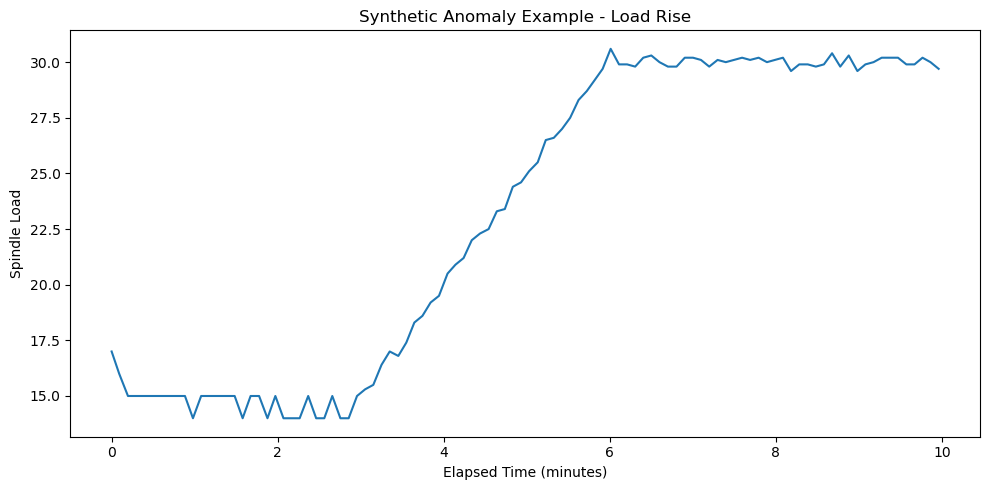

저장 완료: ..\reports\synthetic\load_rise_example.png


In [9]:
from pathlib import Path
import matplotlib.pyplot as plt


# =========================================================
# 그래프 저장 폴더
# =========================================================

synthetic_report_dir = Path("../reports/synthetic")
synthetic_report_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# =========================================================
# load_rise가 포함된 예시 Segment 하나 선택
# =========================================================

load_segment_id = synthetic_df.loc[
    synthetic_df["anomaly_type"] == "load_rise",
    "source_segment_id",
].iloc[0]


load_example = synthetic_df[
    synthetic_df["source_segment_id"] == load_segment_id
].copy()


# 시간 형식 변환
load_example["timestamp"] = pd.to_datetime(
    load_example["timestamp"]
)

load_example = load_example.sort_values(
    "timestamp"
)


# 시작 시점으로부터 몇 분 지났는지 계산
load_example["elapsed_min"] = (
    load_example["timestamp"]
    - load_example["timestamp"].min()
).dt.total_seconds() / 60


print("선택 Segment ID:", load_segment_id)
print("공구:", load_example["current_tool"].iloc[0])

print("\nAnomaly Type 분포:")
print(
    load_example["anomaly_type"].value_counts()
)

print("\nStage 분포:")
print(
    load_example["stage"].value_counts()
)


# =========================================================
# 그래프
# =========================================================

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    load_example["elapsed_min"],
    load_example["spindle_load"],
)

ax.set_title("Synthetic Anomaly Example - Load Rise")
ax.set_xlabel("Elapsed Time (minutes)")
ax.set_ylabel("Spindle Load")

plt.tight_layout()

save_path = (
    synthetic_report_dir
    / "load_rise_example.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

선택 Segment ID: 1
공구: 14

Anomaly Type 분포:
anomaly_type
rpm_instability    71
normal             31
Name: count, dtype: int64

Stage 분포:
stage
anomaly    41
normal     31
warning    30
Name: count, dtype: int64


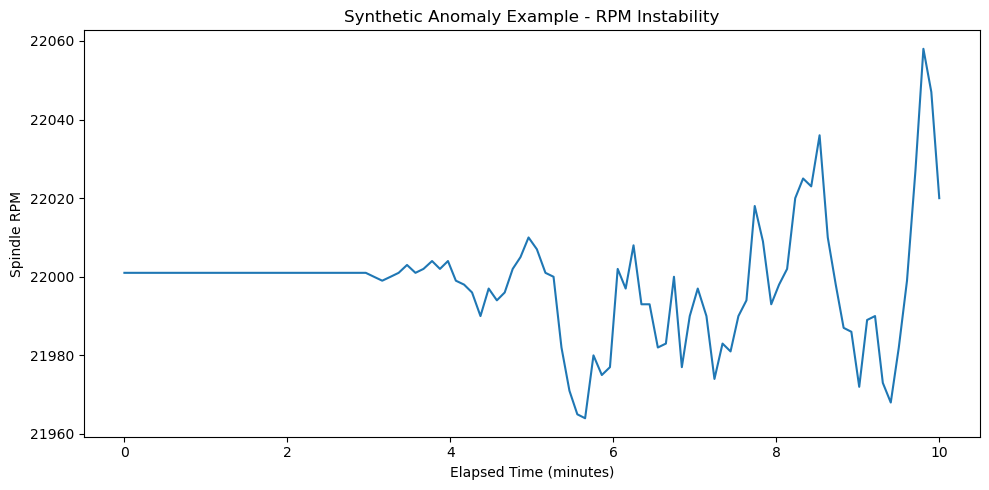

저장 완료: ..\reports\synthetic\rpm_instability_example.png


In [10]:
from pathlib import Path
import matplotlib.pyplot as plt


# =========================================================
# 그래프 저장 폴더
# =========================================================

synthetic_report_dir = Path("../reports/synthetic")
synthetic_report_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# =========================================================
# rpm_instability가 포함된 예시 Segment 하나 선택
# =========================================================

rpm_segment_id = synthetic_df.loc[
    synthetic_df["anomaly_type"] == "rpm_instability",
    "source_segment_id",
].iloc[0]


rpm_example = synthetic_df[
    synthetic_df["source_segment_id"] == rpm_segment_id
].copy()


# 시간 형식 변환
rpm_example["timestamp"] = pd.to_datetime(
    rpm_example["timestamp"]
)

rpm_example = rpm_example.sort_values(
    "timestamp"
)


# 시작 시점으로부터 몇 분 지났는지 계산
rpm_example["elapsed_min"] = (
    rpm_example["timestamp"]
    - rpm_example["timestamp"].min()
).dt.total_seconds() / 60


print("선택 Segment ID:", rpm_segment_id)
print("공구:", rpm_example["current_tool"].iloc[0])

print("\nAnomaly Type 분포:")
print(
    rpm_example["anomaly_type"].value_counts()
)

print("\nStage 분포:")
print(
    rpm_example["stage"].value_counts()
)


# =========================================================
# 그래프
# =========================================================

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    rpm_example["elapsed_min"],
    rpm_example["spindle_rpm"],
)

ax.set_title("Synthetic Anomaly Example - RPM Instability")
ax.set_xlabel("Elapsed Time (minutes)")
ax.set_ylabel("Spindle RPM")

plt.tight_layout()

save_path = (
    synthetic_report_dir
    / "rpm_instability_example.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)

선택 Segment ID: 8
공구: 1

Anomaly Type 분포:
anomaly_type
rpm_error_drift    75
normal             33
Name: count, dtype: int64

Stage 분포:
stage
anomaly    43
normal     33
warning    32
Name: count, dtype: int64


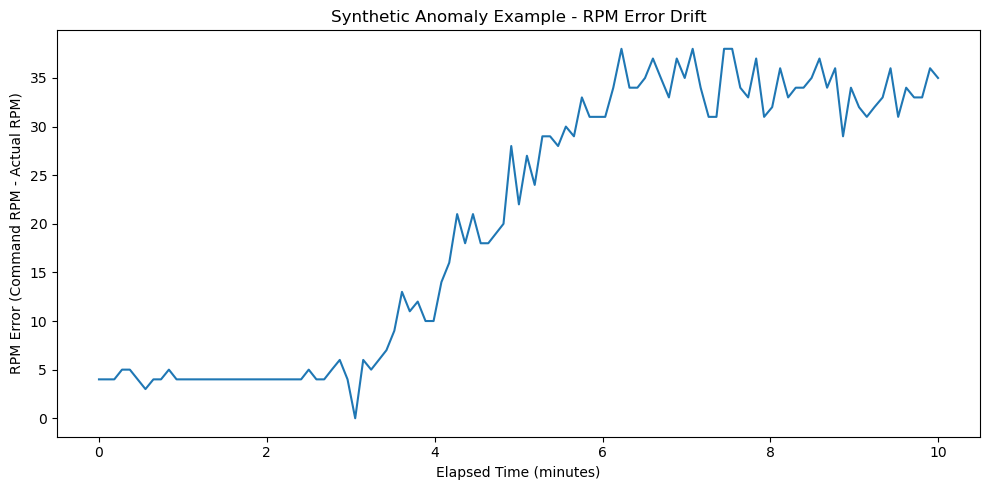

저장 완료: ..\reports\synthetic\rpm_error_drift_example.png


In [11]:
# =========================================================
# rpm_error_drift 예시 Segment 하나 선택
# =========================================================

error_segment_id = synthetic_df.loc[
    synthetic_df["anomaly_type"] == "rpm_error_drift",
    "source_segment_id",
].iloc[0]


error_example = synthetic_df[
    synthetic_df["source_segment_id"] == error_segment_id
].copy()


error_example["timestamp"] = pd.to_datetime(
    error_example["timestamp"]
)

error_example = error_example.sort_values(
    "timestamp"
)


# 경과 시간
error_example["elapsed_min"] = (
    error_example["timestamp"]
    - error_example["timestamp"].min()
).dt.total_seconds() / 60


# 명령 RPM - 실제 RPM
error_example["rpm_error"] = (
    error_example["spindle_rate"]
    - error_example["spindle_rpm"]
)


print("선택 Segment ID:", error_segment_id)
print("공구:", error_example["current_tool"].iloc[0])

print("\nAnomaly Type 분포:")
print(
    error_example["anomaly_type"].value_counts()
)

print("\nStage 분포:")
print(
    error_example["stage"].value_counts()
)


# =========================================================
# 그래프
# =========================================================

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    error_example["elapsed_min"],
    error_example["rpm_error"],
)

ax.set_title("Synthetic Anomaly Example - RPM Error Drift")
ax.set_xlabel("Elapsed Time (minutes)")
ax.set_ylabel("RPM Error (Command RPM - Actual RPM)")

plt.tight_layout()

save_path = (
    synthetic_report_dir
    / "rpm_error_drift_example.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("저장 완료:", save_path)